In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
warnings.filterwarnings('ignore', category=RuntimeWarning)   # empty slices where a whole row was dropped
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score

DATA = '../data'
X_train = np.load(f'{DATA}/train_cadences.npy', mmap_mode='r')   # (18000, 6, 16, 128) uint8
X_test  = np.load(f'{DATA}/test_cadences.npy', mmap_mode='r')    # (10000, 6, 16, 128) uint8
train = pd.read_csv(f'{DATA}/train_meta.csv')
test  = pd.read_csv(f'{DATA}/test_meta.csv')
print(X_train.shape, X_test.shape)
print(train.label.value_counts().to_dict())

(18000, 6, 16, 128) (10000, 6, 16, 128)
{'noise': 4211, 'rfi_persistent': 2892, 'rfi_intermittent': 2662, 'radar_chirp': 1849, 'satellite_pass': 1805, 'pulsar': 1629, 'scintillating_star': 1431, 'frb': 1042, 'eti_candidate': 479}


In [2]:
from pathlib import Path

FEATURE_DIR = Path("../outputs/features")

F_e1_train = pd.read_pickle(FEATURE_DIR / "F_e1_train.pkl")
F_e1_test = pd.read_pickle(FEATURE_DIR / "F_e1_test.pkl")

# Load labels and test IDs for this notebook.
train = pd.read_csv("../data/train_meta.csv")
test = pd.read_csv("../data/test_meta.csv")

assert len(F_e1_train) == len(train)
assert len(F_e1_test) == len(test)
assert F_e1_train.columns.equals(F_e1_test.columns)

print("E1 train features:", F_e1_train.shape)
print("E1 test features:", F_e1_test.shape)

E1 train features: (18000, 65)
E1 test features: (10000, 65)


In [6]:
import importlib
import src.drift_features as df_module

importlib.reload(df_module)
drift_features = df_module.drift_features

In [7]:
D_train = drift_features(X_train)
D_test = drift_features(X_test)

print("Train drift features:", D_train.shape)
print("Test drift features:", D_test.shape)

display(D_train.head())

Processed 128/18000
Processed 256/18000
Processed 384/18000
Processed 512/18000
Processed 640/18000
Processed 768/18000
Processed 896/18000
Processed 1024/18000
Processed 1152/18000
Processed 1280/18000
Processed 1408/18000
Processed 1536/18000
Processed 1664/18000
Processed 1792/18000
Processed 1920/18000
Processed 2048/18000
Processed 2176/18000
Processed 2304/18000
Processed 2432/18000
Processed 2560/18000
Processed 2688/18000
Processed 2816/18000
Processed 2944/18000
Processed 3072/18000
Processed 3200/18000
Processed 3328/18000
Processed 3456/18000
Processed 3584/18000
Processed 3712/18000
Processed 3840/18000
Processed 3968/18000
Processed 4096/18000
Processed 4224/18000
Processed 4352/18000
Processed 4480/18000
Processed 4608/18000
Processed 4736/18000
Processed 4864/18000
Processed 4992/18000
Processed 5120/18000
Processed 5248/18000
Processed 5376/18000
Processed 5504/18000
Processed 5632/18000
Processed 5760/18000
Processed 5888/18000
Processed 6016/18000
Processed 6144/18000

,drift_p0_score,drift_p0_start,drift_p0_slope,drift_p0_mean,drift_p0_coverage,drift_p1_score,drift_p1_start,drift_p1_slope,drift_p1_mean,drift_p1_coverage,...,drift_p4_score,drift_p4_start,drift_p4_slope,drift_p4_mean,drift_p4_coverage,drift_p5_score,drift_p5_start,drift_p5_slope,drift_p5_mean,drift_p5_coverage
0,7.647059,64.0,0.0,1.911765,1.0,7.450000,64.0,-1.0,1.862500,1.0,...,8.374999,64.0,0.0,2.093750,1.0000,8.291667,64.0,0.0,2.072917,1.0
1,8.485294,64.0,0.0,2.121324,1.0,7.558823,64.0,0.0,1.889706,1.0,...,8.888890,53.0,-1.5,2.222223,1.0000,7.597223,64.0,0.0,1.899306,1.0
2,8.075000,88.0,0.0,2.018750,1.0,8.500000,90.0,0.0,2.125000,1.0,...,9.125000,95.0,0.0,2.281250,1.0000,9.973685,96.0,0.0,2.493421,1.0
3,8.157894,64.0,0.0,2.039474,1.0,7.368421,64.0,0.0,1.842105,1.0,...,8.573529,64.0,0.0,2.143382,1.0000,9.426471,64.0,0.0,2.356618,1.0
4,7.680556,64.0,0.0,1.920139,1.0,7.970588,64.0,0.0,1.992647,1.0,...,7.868272,64.0,0.0,2.031579,0.9375,8.000000,64.0,0.0,2.000000,1.0


In [8]:
from pathlib import Path

FEATURE_DIR = Path("../outputs/features")
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

D_train.to_pickle(FEATURE_DIR / "D_train.pkl")
D_test.to_pickle(FEATURE_DIR / "D_test.pkl")

In [9]:
import pandas as pd

FEATURE_DIR = Path("../outputs/features")

F_e1_train = pd.read_pickle(FEATURE_DIR / "F_e1_train.pkl")
F_e1_test = pd.read_pickle(FEATURE_DIR / "F_e1_test.pkl")

D_train = pd.read_pickle(FEATURE_DIR / "D_train.pkl")
D_test = pd.read_pickle(FEATURE_DIR / "D_test.pkl")

assert len(F_e1_train) == len(D_train) == len(train)
assert len(F_e1_test) == len(D_test) == len(test)

F_e2_train = pd.concat(
    [F_e1_train.reset_index(drop=True), D_train.reset_index(drop=True)],
    axis=1
)
F_e2_test = pd.concat(
    [F_e1_test.reset_index(drop=True), D_test.reset_index(drop=True)],
    axis=1
)

assert F_e2_train.columns.is_unique
assert F_e2_train.columns.equals(F_e2_test.columns)

print("E2 train:", F_e2_train.shape)
print("E2 test:", F_e2_test.shape)

E2 train: (18000, 95)
E2 test: (10000, 95)


In [24]:
import pandas as pd
import numpy as np

# Check each panel's preferred drift rate and starting channel
for p in range(6):
    slope = D_train[f"drift_p{p}_slope"]
    start = D_train[f"drift_p{p}_start"]
    score = D_train[f"drift_p{p}_score"]
    coverage = D_train[f"drift_p{p}_coverage"]

    print(f"\nPanel {p}")
    print(f"  Zero-slope rate:       {(slope == 0).mean():.1%}")
    print(f"  Most common slopes:\n{slope.value_counts(normalize=True).head(5).round(3)}")
    print(f"  Most common start channels:\n{start.value_counts(normalize=True).head(5).round(3)}")
    print(f"  Mean drift score:      {score.mean():.3f}")
    print(f"  Mean coverage:         {coverage.mean():.3f}")


Panel 0
  Zero-slope rate:       95.3%
  Most common slopes:
drift_p0_slope
 0.0    0.953
-0.5    0.022
 0.5    0.022
-1.0    0.001
 1.0    0.001
Name: proportion, dtype: float64
  Most common start channels:
drift_p0_start
64.0    0.764
30.0    0.006
29.0    0.006
86.0    0.006
28.0    0.006
Name: proportion, dtype: float64
  Mean drift score:      8.876
  Mean coverage:         0.998

Panel 1
  Zero-slope rate:       96.4%
  Most common slopes:
drift_p1_slope
 0.0    0.964
-0.5    0.017
 0.5    0.017
 2.0    0.000
-1.0    0.000
Name: proportion, dtype: float64
  Most common start channels:
drift_p1_start
64.0     0.796
30.0     0.006
29.0     0.006
28.0     0.005
113.0    0.005
Name: proportion, dtype: float64
  Mean drift score:      8.852
  Mean coverage:         0.998

Panel 2
  Zero-slope rate:       95.6%
  Most common slopes:
drift_p2_slope
 0.0    0.956
 0.5    0.021
-0.5    0.020
-1.0    0.001
 1.0    0.001
Name: proportion, dtype: float64
  Most common start channels:
drift

In [25]:
on_panels = [0, 2, 4]
off_panels = [1, 3, 5]

on_scores = D_train[
    [f"drift_p{p}_score" for p in on_panels]
].mean(axis=1)

off_scores = D_train[
    [f"drift_p{p}_score" for p in off_panels]
].mean(axis=1)

print("Mean ON drift score: ", round(on_scores.mean(), 3))
print("Mean OFF drift score:", round(off_scores.mean(), 3))
print("Median ON drift score: ", round(on_scores.median(), 3))
print("Median OFF drift score:", round(off_scores.median(), 3))

Mean ON drift score:  8.845
Mean OFF drift score: 8.798
Median ON drift score:  7.968
Median OFF drift score: 7.98


In [ ]:
from sklearn.metrics import f1_score, classification_report

X_tr, X_va, y_tr, y_va = train_test_split(
    F_e2_train,
    train["label"],
    test_size=0.2,
    stratify=train["label"],
    random_state=42
)

model_e2 = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.02,
    class_weight="balanced",
    random_state=0
)

model_e2.fit(X_tr, y_tr)
pred_e2 = model_e2.predict(X_va)

print("E2 validation macro-F1:",
      f1_score(y_va, pred_e2, average="macro"))

print(classification_report(y_va, pred_e2, zero_division=0))

E2 validation macro-F1: 0.5837789804806506


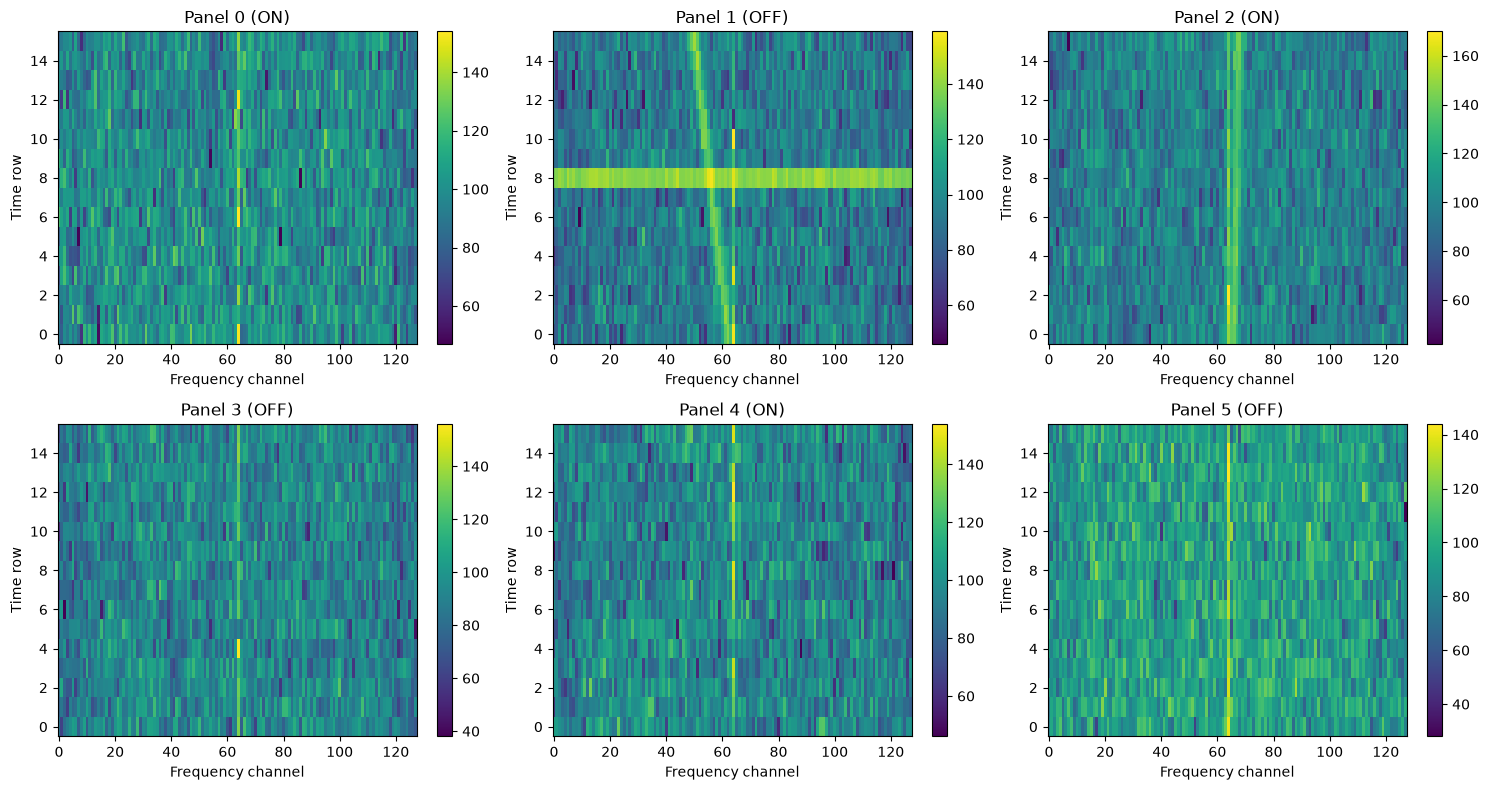

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Choose one training example
i = 0

raw = X_train[i].astype(np.float32)
raw[raw == 0] = np.nan

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for p, ax in enumerate(axes.flat):
    im = ax.imshow(
        raw[p],
        aspect="auto",
        origin="lower",
        interpolation="nearest"
    )
    ax.set_title(f"Panel {p} ({'ON' if p % 2 == 0 else 'OFF'})")
    ax.set_xlabel("Frequency channel")
    ax.set_ylabel("Time row")
    fig.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()

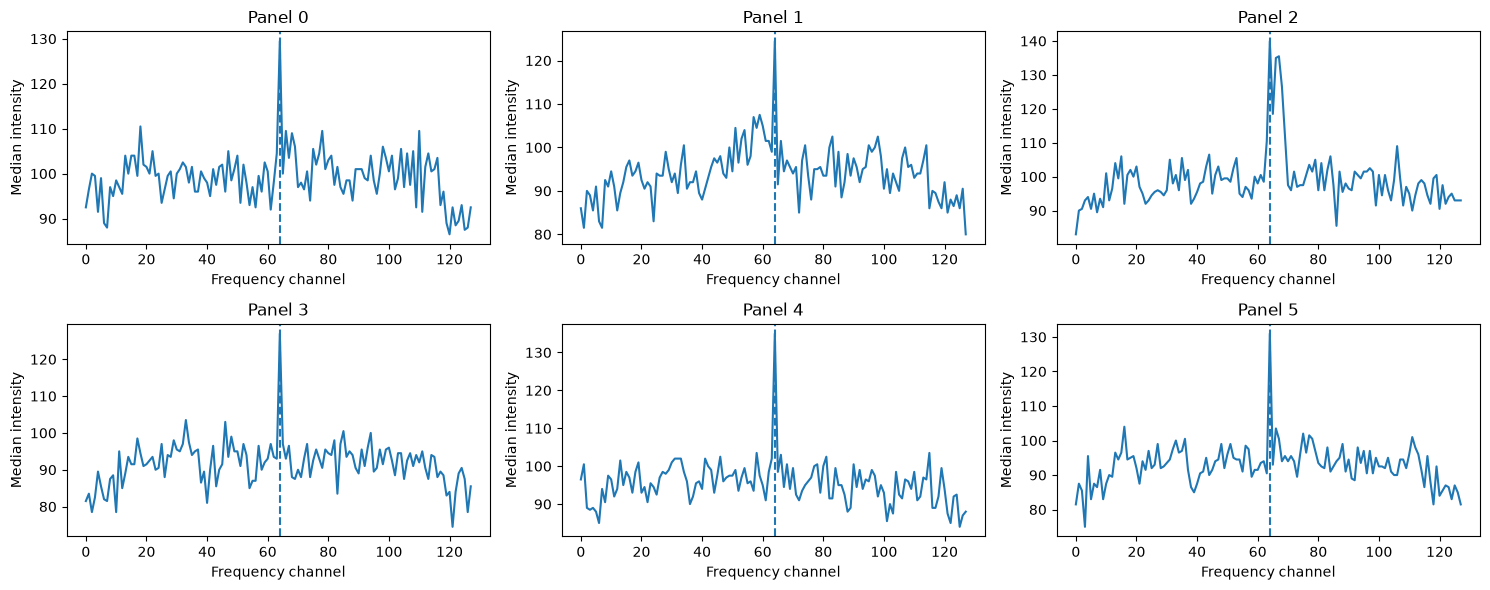

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6))

for p, ax in enumerate(axes.flat):
    profile = np.nanmedian(raw[p], axis=0)
    ax.plot(np.arange(128), profile)
    ax.axvline(64, linestyle="--")
    ax.set_title(f"Panel {p}")
    ax.set_xlabel("Frequency channel")
    ax.set_ylabel("Median intensity")

plt.tight_layout()
plt.show()

In [28]:
import importlib
import src.drift_features as df_module

importlib.reload(df_module)
drift_features_v2 = df_module.drift_features_v2

In [29]:
D2_train = drift_features_v2(X_train)
D2_test = drift_features_v2(X_test)

Processed 128/18000
Processed 256/18000
Processed 384/18000
Processed 512/18000
Processed 640/18000
Processed 768/18000
Processed 896/18000
Processed 1024/18000
Processed 1152/18000
Processed 1280/18000
Processed 1408/18000
Processed 1536/18000
Processed 1664/18000
Processed 1792/18000
Processed 1920/18000
Processed 2048/18000
Processed 2176/18000
Processed 2304/18000
Processed 2432/18000
Processed 2560/18000
Processed 2688/18000
Processed 2816/18000
Processed 2944/18000
Processed 3072/18000
Processed 3200/18000
Processed 3328/18000
Processed 3456/18000
Processed 3584/18000
Processed 3712/18000
Processed 3840/18000
Processed 3968/18000
Processed 4096/18000
Processed 4224/18000
Processed 4352/18000
Processed 4480/18000
Processed 4608/18000
Processed 4736/18000
Processed 4864/18000
Processed 4992/18000
Processed 5120/18000
Processed 5248/18000
Processed 5376/18000
Processed 5504/18000
Processed 5632/18000
Processed 5760/18000
Processed 5888/18000
Processed 6016/18000
Processed 6144/18000

In [30]:
from pathlib import Path

FEATURE_DIR = Path("../outputs/features")
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

D2_train.to_pickle(FEATURE_DIR / "D2_train.pkl")
D2_test.to_pickle(FEATURE_DIR / "D2_test.pkl")

In [31]:
for p in range(6):
    slope = D2_train[f"v2_drift_p{p}_slope"]
    start = D2_train[f"v2_drift_p{p}_start"]

    print(
        f"Panel {p}: "
        f"zero slope = {(slope == 0).mean():.1%}, "
        f"channel 64 = {(start == 64).mean():.1%}"
    )

Panel 0: zero slope = 0.8%, channel 64 = 0.8%
Panel 1: zero slope = 0.4%, channel 64 = 0.9%
Panel 2: zero slope = 0.7%, channel 64 = 0.9%
Panel 3: zero slope = 0.4%, channel 64 = 0.8%
Panel 4: zero slope = 0.7%, channel 64 = 0.9%
Panel 5: zero slope = 0.3%, channel 64 = 0.9%


In [32]:
import pandas as pd

F_e1_train = pd.read_pickle(FEATURE_DIR / "F_e1_train.pkl")
F_e1_test = pd.read_pickle(FEATURE_DIR / "F_e1_test.pkl")

F_e2v2_train = pd.concat(
    [F_e1_train.reset_index(drop=True),
     D2_train.reset_index(drop=True)],
    axis=1
)

F_e2v2_test = pd.concat(
    [F_e1_test.reset_index(drop=True),
     D2_test.reset_index(drop=True)],
    axis=1
)

assert F_e2v2_train.columns.equals(F_e2v2_test.columns)
assert len(F_e2v2_train) == len(train)
assert len(F_e2v2_test) == len(test)

print(F_e2v2_train.shape, F_e2v2_test.shape)

(18000, 89) (10000, 89)


In [36]:


X_tr, X_va, y_tr, y_va = train_test_split(
    F_e2v2_train,
    train["label"],
    test_size=0.2,
    stratify=train["label"],
    random_state=42
)

model_e2v2 = HistGradientBoostingClassifier(
    max_iter=300,
    learning_rate=0.02,
    class_weight="balanced",
    random_state=0
)

model_e2v2.fit(X_tr, y_tr)
pred_e2v2 = model_e2v2.predict(X_va)

score_e2v2 = f1_score(y_va, pred_e2v2, average="macro")
print("E2-v2 validation macro-F1:", score_e2v2)
# print(classification_report(y_va, pred_e2v2, zero_division=0))

E2-v2 validation macro-F1: 0.598588393776578


In [37]:
from pathlib import Path

FEATURE_DIR = Path("../outputs/features")
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

F_e2v2_train.to_pickle(FEATURE_DIR / "F_e2v2_train.pkl")
F_e2v2_test.to_pickle(FEATURE_DIR / "F_e2v2_test.pkl")

In [38]:
best_e2v2_params = {
    "max_iter": 300,
    "learning_rate": 0.02,
    "class_weight": "balanced",
    "random_state": 0,
}